# In-plane torsional buckling of clamped annular plates (Hamada and Harima 1986)

Hamada and Harima [1] computed, with finite differences, the torque at which an annular plate
loaded by in-plane shear on its edges buckles, for all combinations of clamped, simply supported
and free edges, and tested steel plates clamped on both edges. This notebook computes the buckling
torque of their specimens with the annular-sector model `annular_clpt_donnell` of panels and
compares it with their experiments (their Fig. 11) and with the Ritz solution of Irie, Yamada and
Tsujino [2], reprinted by Bagheri, Kiani and Eslami [3].

The same problem, a torque transmitted through the web of a ring frame, appears in the frames of
stiffened cylinders under torsion.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import panels
from panels.shell import Shell
from panels.multidomain import MultiDomain

%matplotlib inline
print('panels', panels.__version__)
T_START = time.time()


def print_table(rows, headers):
    cols = list(zip(*([headers] + [[str(c) for c in r] for r in rows])))
    widths = [max(len(c) for c in col) for col in cols]
    fmt = '  '.join('%%%ds' % w for w in widths)
    print(fmt % tuple(headers))
    print('  '.join('-'*w for w in widths))
    for r in rows:
        print(fmt % tuple(str(c) for c in r))


def rel(value, ref):
    # relative difference in per cent
    return 100.*(value - ref)/ref

panels 0.15.0


## 1. Specimens and dimensionless torque

From [1], Sec. 4.2: annular plates cut from a steel plate SS41 of thickness $h = 0.5$ mm; the outer
part clamped in a stiff frame, the outer diameter of the specimen being 448 mm; the central part
clamped by stiff round bosses of three diameters, so that the ratios of the outer to the inner
diameter are $D_o/D_i = 5, 6, 7$, two specimens per ratio. The outer frame was fixed and the
central boss rotated by a torsion testing machine.

The buckling torque is given in the dimensionless form of [1], Eq. (9),

$$S = \frac{T}{\pi D}, \qquad D = \frac{E h^3}{12 (1 - \nu^2)}$$

$D$ being the flexural rigidity. Irie et al. [2] use $\tau_B = T_B/(2 \pi D) = S/2$, with $\beta$ the
ratio of the inner to the outer radius, $\beta = D_i/D_o$.

[1] gives neither Young's modulus nor Poisson's ratio of the steel. $S$ does not depend on $E$: the
pre-buckling membrane forces and the geometric stiffness are proportional to $T$, the bending
stiffness to $D$. For a plate clamped on both edges it does not depend on $\nu$ either, the bending
energy of a clamped plate being $\frac{D}{2} \int (\nabla^2 w)^2 \, dA$; Section 4 checks it. The
values below are therefore only a convenient choice.

In [2]:
H = 0.5                  # mm, [1] Sec. 4.2
R_OUT = 448./2           # mm, outer diameter 448 mm, [1] Sec. 4.2
RATIOS = (5, 6, 7)       # D_o/D_i of the specimens, [1] Sec. 4.2
E = 206e3                # N/mm^2, not given in [1]: S does not depend on it
NU = 0.3                 # not given in [1]: S does not depend on it (Section 4)


def flexural_rigidity(nu=NU):
    return E*H**3/(12*(1 - nu**2))

## 2. Pre-buckling state and model

A torque $T$ applied to one edge of the annulus and reacted on the other gives, by the equilibrium
of moments about the centre of the part of the plate inside the radius $\rho$, the membrane state

$$N_{\rho\rho} = N_{\theta\theta} = 0, \qquad N_{\rho\theta} = \frac{T}{2 \pi \rho^2}$$

whatever the in-plane edge conditions ([3], Eqs. (10) and (12)); the shear is largest at the inner
edge. The buckling torque therefore does not depend on which edge the torque is applied to. In the
model the inner edge is fixed in its plane and the outer edge carries the tangential force per unit
length $q = T/(2 \pi r^2)$, $r$ being the outer radius, along which the coordinate $y$ of the
annular sector is the arc length.

The full annulus is made of two half annuli of `annular_clpt_donnell`, the classical plate theory in
polar coordinates, whose radial edges are free and connected with `'SSycte'`; both circular edges
are clamped, $w = w_{,\rho} = 0$. In the coordinates of the sector, $x = r - \rho$ runs from the
outer edge inwards and $N_{xy} = -N_{\rho\theta}$. Each displacement field is a Ritz series of
Bardell's hierarchical functions, $m$ terms along the radius and $n$ along each half circumference
[4].

The linear static solution $\boldsymbol{c}$ for the load $T$ gives the geometric stiffness
$\boldsymbol{K}_G(\boldsymbol{c})$, and the buckling torque is $\lambda T$ with the least $|\lambda|$
of $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G) \boldsymbol{\phi} = \boldsymbol{0}$
(`MultiDomain.linear_buckling`). The critical values come in pairs of opposite sign, an isotropic
plate buckling under a torque of either sense.

In [3]:
def annulus(beta, T, m, n, nu=NU, inner='C', outer='C'):
    flags = {'C': (0, 0), 'SS': (0, 1), 'F': (1, 1)}
    halves = []
    for _ in range(2):
        s = Shell(model='annular_clpt_donnell', a=R_OUT*(1 - beta), b=np.pi*R_OUT,
                  r=R_OUT, m=m, n=n, plyt=H, stack=[0], laminaprop=(E, nu))
        for e in ('y1', 'y2'):
            for f in ('u', 'v', 'w', 'ur', 'vr', 'wr'):
                setattr(s, e + f, 1)
        s.x1u = s.x1v = 1                 # outer edge free in its plane, loaded
        s.x2u = s.x2v = 0                 # inner edge fixed in its plane
        s.x1w, s.x1wr = flags[outer]
        s.x2w, s.x2wr = flags[inner]
        s.add_distr_load_fixed_x(0., funcy=lambda y: T/(2*np.pi*R_OUT**2) + 0*y)
        halves.append(s)
    p1, p2 = halves
    conn = [dict(p1=p1, p2=p2, func='SSycte', ycte1=p1.b, ycte2=0),
            dict(p1=p1, p2=p2, func='SSycte', ycte1=0, ycte2=p2.b)]
    return MultiDomain([p1, p2], conn)


def buckling(beta, m, n, nu=NU, **kwargs):
    # S = T/(pi D) of the least |lambda| for T = pi D, and the first mode
    T = np.pi*flexural_rigidity(nu)
    md = annulus(beta, T, m, n, nu=nu, **kwargs)
    eigvals, eigvecs = md.linear_buckling(num_eigvalues=6, silent=True)
    i = np.argmin(np.abs(eigvals))
    return abs(eigvals[i]), md, eigvecs[:, i]

The membrane state of the linear static case against $N_{xy} = -T/(2 \pi \rho^2)$, for $D_o/D_i =
5$, along a radius of the first half annulus:

In [4]:
T = 1.e3                 # N mm
md = annulus(1/5, T, m=12, n=16)
c = md.linear_static()
s = md.panels[0]
xs = np.linspace(0, s.a, 7)[:, None]*np.ones((1, 1))
ys = np.full_like(xs, s.b/3)
Nxy = s.stress(c[s.col_start:s.col_end], xs=xs, ys=ys, NLgeom=False)[1]['Nxy']
rows = []
for x, N in zip(xs.ravel(), Nxy.ravel()):
    ref = -T/(2*np.pi*(R_OUT - x)**2)
    rows.append(['%.1f' % (R_OUT - x), '%.5f' % N, '%.5f' % ref, '%+.3f' % rel(N, ref)])
print_table(rows, ['rho (mm)', 'Nxy panels (N/mm)', '-T/(2 pi rho^2)', 'diff (%)'])

rho (mm)  Nxy panels (N/mm)  -T/(2 pi rho^2)  diff (%)
--------  -----------------  ---------------  --------
   224.0           -0.00318         -0.00317    +0.181
   194.1           -0.00422         -0.00422    -0.036
   164.3           -0.00590         -0.00590    +0.024
   134.4           -0.00881         -0.00881    -0.002
   104.5           -0.01456         -0.01457    -0.013
    74.7           -0.02855         -0.02855    +0.016
    44.8           -0.07927         -0.07930    -0.039


## 3. Convergence

The number of terms along the radius, $m$, and along each half circumference, $n$, is increased for
the three ratios. The buckling modes are spirals with a few waves around the circumference ([1],
Fig. 8; [2], Table 1).

In [5]:
MESHES = [(8, 12), (10, 14), (12, 16), (14, 18), (16, 20)]
S = {}
for ratio in RATIOS:
    rows = []
    prev = None
    for m, n in MESHES:
        S[(ratio, m, n)] = buckling(1/ratio, m, n)[0]
        change = '' if prev is None else '%+.4f' % rel(S[(ratio, m, n)], prev)
        rows.append([m, n, '%.3f' % S[(ratio, m, n)], change])
        prev = S[(ratio, m, n)]
    print('D_o/D_i = %d' % ratio)
    print_table(rows, ['m', 'n', 'S', 'change (%)'])
    print()
M_FIN, N_FIN = MESHES[-1]

D_o/D_i = 5
 m   n       S  change (%)
--  --  ------  ----------
 8  12  73.231            
10  14  71.983     -1.7036
12  16  71.971     -0.0167
14  18  71.969     -0.0030
16  20  71.968     -0.0008



D_o/D_i = 6
 m   n       S  change (%)
--  --  ------  ----------
 8  12  58.486            
10  14  57.017     -2.5127
12  16  56.988     -0.0497
14  18  56.988     -0.0013
16  20  56.987     -0.0010



D_o/D_i = 7
 m   n       S  change (%)
--  --  ------  ----------
 8  12  49.866            
10  14  48.105     -3.5318
12  16  48.035     -0.1442
14  18  48.035     -0.0013
16  20  48.034     -0.0013



## 4. Independence of Poisson's ratio

For both edges clamped the critical torque in terms of $D$ should not depend on $\nu$:

In [6]:
rows = []
for ratio in RATIOS:
    S_nu = buckling(1/ratio, M_FIN, N_FIN, nu=0.25)[0]
    rows.append([ratio, '%.3f' % S[(ratio, M_FIN, N_FIN)], '%.3f' % S_nu,
                 '%+.4f' % rel(S_nu, S[(ratio, M_FIN, N_FIN)])])
print_table(rows, ['D_o/D_i', 'S, nu = 0.3', 'S, nu = 0.25', 'diff (%)'])

D_o/D_i  S, nu = 0.3  S, nu = 0.25  diff (%)
-------  -----------  ------------  --------
      5       71.968        71.968   -0.0000
      6       56.987        56.987   -0.0000
      7       48.034        48.034   +0.0000


## 5. Comparison with the Ritz solution of Irie et al.

$D_o/D_i = 5$ is $\beta = 0.2$ of the table of Irie, Yamada and Tsujino [2] (Table 1, C-C,
$\tau_B = 36.02$, three waves), reprinted by Bagheri, Kiani and Eslami [3] (Table 1) beside their
own differential-quadrature value 35.982. The other two ratios are not in [2]; the table also
compares the clamped annuli of [2] for $\beta = 0.1$ to $0.5$.

In [7]:
IRIE_CC = {0.1: 17.55, 0.2: 36.02, 0.3: 61.97, 0.4: 106.3, 0.5: 186.1}   # [2] Table 1
BAGHERI_CC = {0.1: 17.454, 0.2: 35.982, 0.3: 61.955, 0.4: 106.271, 0.5: 186.051}  # [3] Table 1
rows = []
for beta, ref in IRIE_CC.items():
    tau = buckling(beta, M_FIN, N_FIN)[0]/2
    rows.append(['%.1f' % beta, '%.3f' % tau, ref, '%+.2f' % rel(tau, ref),
                 BAGHERI_CC[beta], '%+.2f' % rel(tau, BAGHERI_CC[beta])])
print_table(rows, ['beta', 'tau_B panels', 'Irie [2]', 'diff (%)', 'Bagheri [3]', 'diff (%)'])

beta  tau_B panels  Irie [2]  diff (%)  Bagheri [3]  diff (%)
----  ------------  --------  --------  -----------  --------
 0.1        17.456     17.55     -0.53       17.454     +0.01
 0.2        35.984     36.02     -0.10       35.982     +0.01
 0.3        61.959     61.97     -0.02       61.955     +0.01
 0.4       106.279     106.3     -0.02      106.271     +0.01
 0.5       186.070     186.1     -0.02      186.051     +0.01


## 6. Comparison with the experiments

[1] reports the experimental buckling torques only as points of its Fig. 11, $S$ against
$D_o/D_i$; each was taken as the asymptote $A$ of $T = A (1 - e^{-B \eta + C})$ fitted to the
measured torque against the angle of torsion $\eta$ ([1], Eq. (31)). The values below were read from
the figure (the centres of the circles of a 600 dpi image of the PDF, the axes calibrated on the
ticks); the reading is accurate to about $\pm 1$ in $S$. The two specimens with $D_o/D_i = 7$ gave
the same value and are drawn as one circle.

D_o/D_i  specimen  S experiment [1]  S panels  diff (%)
-------  --------  ----------------  --------  --------
      5         1              88.5     71.97     -18.7
      5         2              81.5     71.97     -11.7
      6         1              60.2     56.99      -5.3
      6         2              52.4     56.99      +8.8
      7         1              44.4     48.03      +8.2
      7         2              44.4     48.03      +8.2


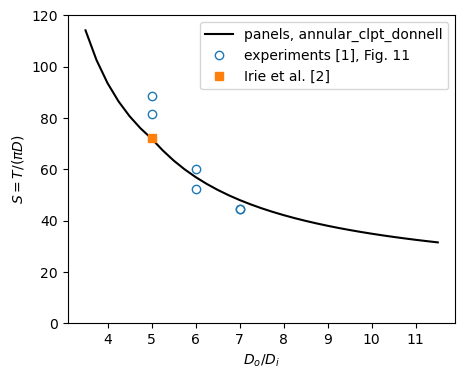

In [8]:
# [1] Fig. 11, read from the figure
S_EXP = {5: (88.5, 81.5), 6: (60.2, 52.4), 7: (44.4, 44.4)}
rows = []
for ratio in RATIOS:
    S_th = S[(ratio, M_FIN, N_FIN)]
    for i, S_e in enumerate(S_EXP[ratio]):
        rows.append([ratio, i + 1, '%.1f' % S_e, '%.2f' % S_th, '%+.1f' % rel(S_th, S_e)])
print_table(rows, ['D_o/D_i', 'specimen', 'S experiment [1]', 'S panels', 'diff (%)'])

ratios = np.linspace(3.5, 11.5, 33)
S_curve = [buckling(1/x, M_FIN, N_FIN)[0] for x in ratios]
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(ratios, S_curve, 'k-', label='panels, annular_clpt_donnell')
for ratio in RATIOS:
    ax.plot([ratio]*2, S_EXP[ratio], 'o', mfc='none', color='C0',
            label='experiments [1], Fig. 11' if ratio == 5 else None)
ax.plot([5], [2*IRIE_CC[0.2]], 's', color='C1', label='Irie et al. [2]')
ax.set_xlabel('$D_o/D_i$')
ax.set_ylabel('$S = T/(\\pi D)$')
ax.set_ylim(0, 120)
ax.legend()
plt.show()

## 7. Buckling mode

The deflection $w$ of the first mode of the plate with $D_o/D_i = 5$, normalized:

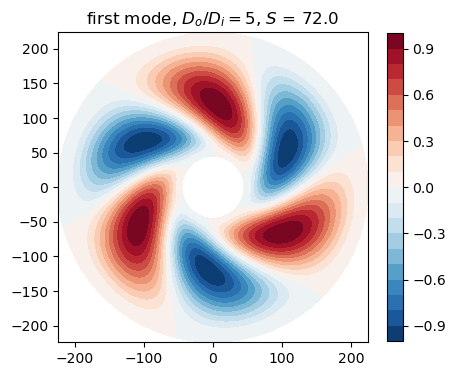

In [9]:
S5, md5, mode = buckling(1/5, M_FIN, N_FIN)
fig, ax = plt.subplots(figsize=(5, 5))
wmax = 0
fields = []
for k, p in enumerate(md5.panels):
    xs, ys = np.meshgrid(np.linspace(0, p.a, 40), np.linspace(0, p.b, 160), indexing='ij')
    w = p.uvw(mode[p.col_start:p.col_end], xs=xs, ys=ys)[1]['w']
    rho = R_OUT - xs
    theta = ys/R_OUT + k*np.pi
    fields.append((rho*np.cos(theta), rho*np.sin(theta), w))
    wmax = max(wmax, np.abs(w).max())
for X, Y, w in fields:
    cs = ax.contourf(X, Y, w/wmax, levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
ax.set_aspect('equal')
ax.set_title('first mode, $D_o/D_i = 5$, $S$ = %.1f' % S5)
fig.colorbar(cs, ax=ax, shrink=0.8)
plt.show()

## 8. Discussion

**Pre-buckling state.** The linear static case reproduces $N_{xy} = -T/(2 \pi \rho^2)$ within
0.04 % inside the plate (0.18 % on the loaded edge).

**Convergence.** From $m = 12$, $n = 16$ on, $S$ changes by less than 0.003 %; the finest mesh,
$m = 16$, $n = 20$, is used for the comparisons. As expected for both edges clamped, $S$ is the same
for $\nu = 0.3$ and $0.25$ to all printed digits.

**Ritz solutions.** panels agrees with the differential-quadrature values of Bagheri et al. [3]
within 0.01 % for $\beta = 0.1$ to $0.5$, and with Irie et al. [2] within 0.10 % for $\beta \ge 0.2$
(0.53 % for $\beta = 0.1$, where [3] differs from [2] by the same amount). For $D_o/D_i = 5$,
$S = 71.97$ is twice $\tau_B = 35.98$ of [2] and [3]; the first mode is a spiral with three waves
around the circumference (Section 7), as $n_B = 3$ of [2].

**Experiments.** The experimental torques of [1] scatter by about 10 % between the two specimens of
the same ratio. panels lies 12 % and 19 % below both specimens of $D_o/D_i = 5$, between the two
specimens of $D_o/D_i = 6$ (-5 % and +9 %) and 8 % above the specimens of $D_o/D_i = 7$; the curve of
[1], Fig. 11, computed with finite differences, passes through the same region. The experimental
values come from an extrapolation of the torque-rotation curves (Eq. (31) of [1]), and [1]
attributes the gradual bending of the measured curves to initial imperfections of the specimens;
the clamping by stiff bosses and frames is also not perfect. Within this scatter the linear buckling
torque of the clamped annulus describes the tests.

## References

1. Hamada, M., and Harima, T., "In-plane torsional buckling of an annular plate", Bulletin of JSME,
   Vol. 29, No. 250, 1986, pp. 1089-1095, Eq. (9), Sec. 4.2, Figs. 8 and 11.
   https://doi.org/10.1299/jsme1958.29.1089
2. Irie, T., Yamada, G., and Tsujino, M., "Buckling loads of annular plates subjected to a torque",
   Journal of Sound and Vibration, Vol. 86, No. 1, 1983, pp. 145-146, Table 1.
   https://doi.org/10.1016/0022-460X(83)90951-3
3. Bagheri, H., Kiani, Y., and Eslami, M. R., "Buckling of moderately thick annular plates subjected
   to torque", Archive of Mechanical Engineering, Vol. 66, No. 2, 2019, pp. 209-227, Eqs. (10),
   (12) and Table 1. https://doi.org/10.24425/ame.2019.128445
4. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear
   buckling and vibration of stiffened composite panels with debonding defect", Composite
   Structures, Vol. 160, 2017, pp. 232-247. https://doi.org/10.1016/j.compstruct.2016.10.026

In [10]:
print('total run time: %.1f min' % ((time.time() - T_START)/60))

total run time: 14.5 min
